# EDA · Propensión de compra por sesión

¿Qué contiene la base, qué problemas de calidad presenta y qué decisiones justifican el pipeline?

Cada fila representa una **sesión web terminada**, no un usuario. El objetivo es estimar la probabilidad de que esa sesión tenga una transacción. Las variables completas de duración y actividad sólo están disponibles al finalizar: este análisis no demuestra capacidad de anticipar compras ni respuesta a campañas.

**Alcance:** estructura y calidad general; relaciones con compra sólo en enero–mayo de 2017. Junio queda fuera del análisis del target y de las decisiones de features, ya que es parte del test set.


## 1. Carga reproducible

Desde la raíz: `uv sync --extra eda`. Abrir con un editor compatible con notebooks y elegir el Python de `.venv`. Ejecutar todas las celdas en orden. Las rutas funcionan desde la raíz o desde `notebooks/`.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from autoresearch_purchase_propensity.preprocess import load_sessions, CATEGORICAL

ROOT = Path.cwd().resolve()
if not (ROOT / "configs/data.json").exists():
    ROOT = ROOT.parent
config = json.loads((ROOT / "configs/data.json").read_text())
raw = pd.read_csv(ROOT / config["raw_path"], dtype={"fullVisitorID": "string"}, low_memory=False)
sessions = load_sessions(ROOT / config["raw_path"], config["missing_transactions_mean_zero"])
analysis = sessions.loc[sessions.date < pd.Timestamp(config["test_start"])].copy()
analysis["month"] = analysis.date.dt.to_period("M").astype(str)
plt.rcParams.update({"figure.figsize": (8, 3), "axes.spines.top": False, "axes.spines.right": False})
display(pd.Series({
    "Sesiones totales": len(raw), "Columnas originales": raw.shape[1],
    "Usuarios observados": raw.fullVisitorID.nunique(),
    "Primera fecha": str(sessions.date.min().date()),
    "Última fecha": str(sessions.date.max().date()),
    "Sesiones enero–mayo": len(analysis),
}, name="Dataset").to_frame())


,Dataset
Sesiones totales,392892
Columnas originales,15
Usuarios observados,308130
Primera fecha,2017-01-01
Última fecha,2017-06-30
Sesiones enero–mayo,329314


## 2. Qué significa cada variable

| Variables | Significado y uso |
|---|---|
| `fullVisitorID` | Identificador del usuario como texto. Para construir historia, no como predictor. |
| `date`, `visitNumber` | Día y número de sesión del usuario. El contador puede reflejar visitas anteriores al período observado. |
| `hits`, `pageviews`, `timeOnSite` | Acciones, páginas y duración en segundos de la sesión completa. |
| `bounces` | 1 indica una sesión sin interacciones; null significa que no fue rebote. |
| `transactions` | Número de transacciones; define `target = transactions > 0`. Null se interpreta como cero por una hipótesis explícita del proyecto. |
| `transactionRevenue` | Ingresos de la sesión. Se excluye porque revela el resultado. No se presupone una unidad monetaria. |
| `source`, `channelGrouping` | Fuente y canal de adquisición. |
| `browser`, `deviceCategory` | Navegador y tipo de dispositivo. |
| `country`, `city` | Ubicación aproximada. Puede incluir valores de disponibilidad limitada. |

El loader valida el esquema, interpreta fechas, convierte contadores y normaliza marcadores categóricos. No se muestran IDs ni filas individuales.


In [2]:
profile = pd.DataFrame({
    "tipo_original": raw.dtypes.astype(str),
    "faltantes_originales_%": raw.isna().mean().mul(100),
    "marcadores_ausencia_%": raw.isin(["(not set)", "not available in demo dataset"]).mean().mul(100),
    "faltantes_normalizados_%": sessions[raw.columns].isna().mean().mul(100),
    "valores_distintos": raw.nunique(),
})
display(profile.round(2))


,tipo_original,faltantes_originales_%,marcadores_ausencia_%,faltantes_normalizados_%,valores_distintos
fullVisitorID,string,0.00,0.00,0.00,308130
visitNumber,int64,0.00,0.00,0.00,376
date,int64,0.00,0.00,0.00,181
bounces,float64,50.12,0.00,0.00,1
hits,int64,0.00,0.00,0.00,198
pageviews,float64,0.01,0.00,0.01,155
timeOnSite,float64,50.01,0.00,50.01,3499
transactionRevenue,float64,98.66,0.00,98.66,3118
transactions,float64,98.66,0.00,98.66,11
source,str,0.00,0.02,0.02,210


**Decisión sobre faltantes:** no reemplazar todos los null por cero. `bounces` tiene una definición especial y `transactions` una hipótesis explícita. La duración desconocida sigue faltante y se imputa dentro del pipeline ajustado sólo con entrenamiento. Los marcadores categóricos se consideran ausencia, no ubicaciones o fuentes reales.


### Política de valores faltantes

Las definiciones suministradas en el PDF confirman explícitamente que **`bounces=null` significa que no hubo rebote**. No definen qué significa un null en `timeOnSite`, `transactions` o `transactionRevenue`; no debemos inventar esa semántica.

| Variable | Tratamiento del proyecto | Justificación |
|---|---|---|
| `bounces` | Null → 0 | Definición explícita; no es duración cero. |
| `transactions` | Null → 0 para construir el target | **Hipótesis del proyecto, no confirmada por el PDF**. Confirmar con la fuente si se utiliza en un caso real. |
| `transactionRevenue` | Excluir de predictores; no imputar para modelar | Revela el resultado de la sesión. Su unidad y null no quedan definidos. |
| `timeOnSite`, `pageviews` | Conservar NaN en datos; indicador de ausencia y mediana ajustada en train en el baseline logístico | “No medido” no equivale a cero. Otros modelos pueden tratar NaN nativamente; debe validarse por experimento. |
| Categóricas | Marcadores de ausencia → null; categoría `__MISSING__` dentro del pipeline | Diferenciar desconocido de una categoría real y soportar categorías nuevas. |
| Usuario, fecha, `hits`, `visitNumber` | Rechazar entradas inválidas según loader | Son campos necesarios para alinear filas e historia; no imputarlos silenciosamente. |

No descartamos una variable automáticamente por su porcentaje de ausencia. La política de cada candidato debe revisarse: un artefacto histórico conserva su preprocesamiento original.


In [3]:
# Sólo entrenamiento: comprobar si la ausencia de duración contiene información.
train_missing = analysis.loc[analysis.date < pd.Timestamp(config["validation_start"])]
duration_groups = train_missing.groupby(train_missing.timeOnSite.isna()).agg(
    sesiones=("target", "size"), compras=("target", "sum"),
    tasa_compra=("target", "mean"), tasa_rebote=("bounces", "mean"),
).rename(index={False: "Duración observada", True: "Duración ausente"})
display(duration_groups.assign(
    tasa_compra_pct=duration_groups.tasa_compra * 100,
    tasa_rebote_pct=duration_groups.tasa_rebote * 100,
).drop(columns=["tasa_compra", "tasa_rebote"]).round(5))


,sesiones,compras,tasa_compra_pct,tasa_rebote_pct
timeOnSite,,,,
Duración observada,130567,3215,2.46234,0.00077
Duración ausente,133376,1,0.00075,99.75933


**Qué hacemos con `timeOnSite`:** en train hay 133.376 sesiones sin duración y sólo una compra; entre las 130.567 con duración hay 3.215 compras. El 99,76 % de las sesiones sin duración son rebotes. Esto muestra asociación y redundancia potencial, no demuestra el mecanismo de medición.

**Recomendación:** conservar por ahora la duración y su indicador de ausencia. No imputar cero ni eliminar la mitad de las sesiones. Para decidir si aporta señal adicional a `hits`, `pageviews` y `bounces`, comparar posteriormente el mismo modelo con: (a) duración + indicador, (b) sólo indicador y (c) ninguna de las dos. Elegir por log loss en validación, no por la correlación de train. No se ejecuta esa comparación aquí.


## 3. Duplicados y consistencia

No tenemos un identificador natural de sesión. Dos sesiones del mismo usuario en el mismo día pueden ser legítimas: esa combinación no autoriza deduplicar.


In [4]:
checks = pd.Series({
    "Filas exactamente duplicadas": int(raw.duplicated().sum()),
    "Filas adicionales con mismo usuario y día": int(raw.duplicated(["fullVisitorID", "date"]).sum()),
    "Filas adicionales con mismo usuario, día y visitNumber": int(raw.duplicated(["fullVisitorID", "date", "visitNumber"]).sum()),
    "Pageviews mayores que hits": int((sessions.pageviews > sessions.hits).sum()),
    "visitNumber menor que 1": int((sessions.visitNumber < 1).sum()),
    "Duración negativa": int((sessions.timeOnSite < 0).sum()),
    "Compra con ingresos ausentes": int((sessions.target.eq(1) & sessions.transactionRevenue.isna()).sum()),
    "Ingresos positivos sin compra": int((sessions.transactionRevenue.gt(0) & sessions.target.eq(0)).sum()),
}, name="Filas")
display(checks.to_frame())


,Filas
Filas exactamente duplicadas,0
Filas adicionales con mismo usuario y día,32798
"Filas adicionales con mismo usuario, día y visitNumber",0
Pageviews mayores que hits,0
visitNumber menor que 1,0
Duración negativa,0
Compra con ingresos ausentes,0
Ingresos positivos sin compra,0


**Decisión:** registrar inconsistencias para revisión, sin eliminar ni corregir filas silenciosamente. `session_row_id`, generado por el pipeline, permite alinear features, etiquetas y predicciones; no es una feature.


## 4. Compra y evolución temporal — enero a mayo

Con una clase positiva poco frecuente, accuracy puede ocultar un modelo que nunca identifica compras. El objetivo de AutoResearch es **log loss**, comparado con la probabilidad constante de entrenamiento; Average Precision es complementaria.


,sesiones,compras,usuarios,tasa_compra_pct
month,,,,
2017-01,64694,697,53041,1.077
2017-02,62192,708,51364,1.138
2017-03,69931,883,57888,1.263
2017-04,67126,928,55681,1.382
2017-05,65371,1115,52233,1.706


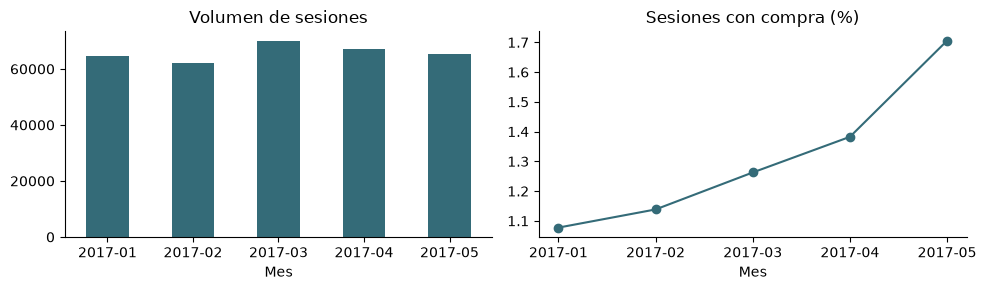

In [5]:
monthly = analysis.groupby("month").agg(
    sesiones=("target", "size"), compras=("target", "sum"),
    usuarios=("fullVisitorID", "nunique"), tasa_compra=("target", "mean"),
)
display(monthly.assign(tasa_compra_pct=monthly.tasa_compra * 100).drop(columns="tasa_compra").round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
monthly.sesiones.plot.bar(ax=axes[0], color="#346b78", rot=0, title="Volumen de sesiones")
monthly.tasa_compra.mul(100).plot(ax=axes[1], marker="o", color="#346b78", title="Sesiones con compra (%)")
for ax in axes:
    ax.set_xlabel("Mes")
fig.tight_layout()
plt.show()


**Decisión:** preservar el orden temporal. Entrenamiento: enero–abril; validación: mayo; junio fuera del loop. Un split aleatorio mezclaría períodos y no reproduciría la evaluación sobre un mes posterior. La gráfica describe cambios observados; no prueba por sí sola una causa de esos cambios.


## 5. Cuánta historia tenemos por usuario

“Nuevo” significa **sin una visita observada en un día anterior**, no necesariamente su primera visita real. La ventana del dataset es limitada. No usamos el contador `visitNumber` como sustituto de historia observada.


,sesiones,con_historia,con_historia_%
month,,,
2017-01,64694,7834,12.11
2017-02,62192,9636,15.49
2017-03,69931,10996,15.72
2017-04,67126,10855,16.17
2017-05,65371,12157,18.60


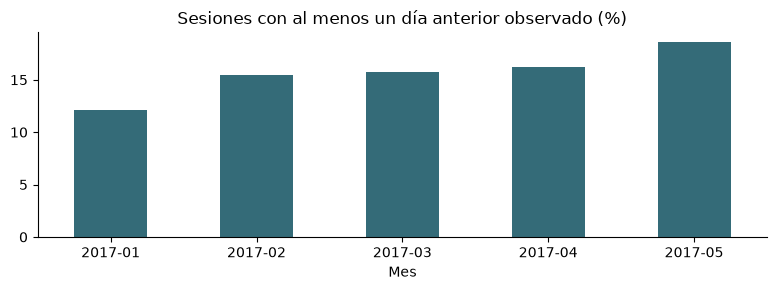

,sesiones,tasa_compra
has_prior_day,,
Sin historia previa,277836,0.0090
Con historia previa,51478,0.0357


In [6]:
first_day = analysis.groupby("fullVisitorID").date.transform("min")
analysis["has_prior_day"] = analysis.date.gt(first_day)
history_by_month = analysis.groupby("month").agg(
    sesiones=("target", "size"), con_historia=("has_prior_day", "sum"),
)
history_by_month["con_historia_%"] = history_by_month.con_historia / history_by_month.sesiones * 100
display(history_by_month.round(2))
history_by_month["con_historia_%"].plot.bar(color="#346b78", rot=0, title="Sesiones con al menos un día anterior observado (%)")
plt.xlabel("Mes")
plt.tight_layout()
plt.show()
display(analysis.groupby("has_prior_day").agg(
    sesiones=("target", "size"), tasa_compra=("target", "mean"),
).rename(index={False: "Sin historia previa", True: "Con historia previa"}).round(4))


**Decisión:** el modelo debe funcionar sin historia. Evaluaremos por separado usuarios con y sin pasado disponible. La historia de mayo puede incluir sesiones de entrenamiento y de días previos de mayo, porque estaban disponibles en ese momento; nunca incluye compras del mismo día ni del futuro. La diferencia entre grupos es asociación, no causalidad.


## 6. Distribuciones y categorías — sólo entrenamiento

Las decisiones de transformación se apoyan en enero–abril. Las colas largas requieren revisar escalas y valores extremos; no implican que debamos eliminar sesiones automáticamente.


,visitNumber,hits,pageviews,timeOnSite
count,263943.00,263943.00,263922.00,130567.00
mean,2.40,4.39,3.76,274.61
std,10.62,8.80,6.65,490.54
min,1.00,1.00,1.00,1.00
50%,1.00,2.00,1.00,93.00
90%,3.00,10.00,9.00,756.00
99%,22.00,40.00,31.00,2301.34
max,374.00,500.00,466.00,12136.00


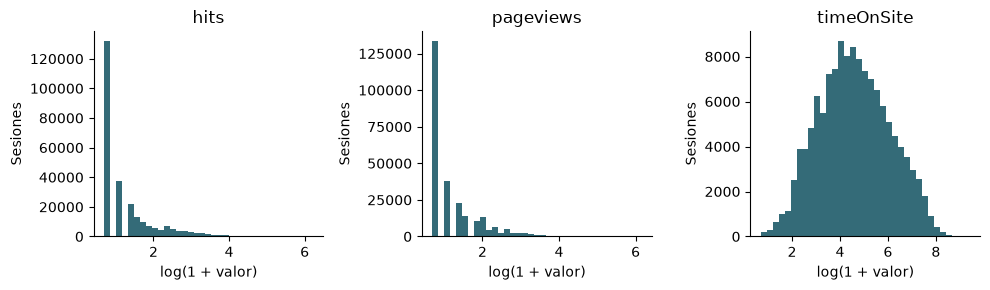

,categorías,faltantes_%
source,187,0.02
channelGrouping,8,0.00
browser,36,0.00
deviceCategory,3,0.00
country,207,0.15
city,357,63.37


,sesiones,tasa_compra
deviceCategory,,
desktop,180956,0.0161
mobile,72720,0.0037
tablet,10267,0.0035


In [7]:
train = analysis.loc[analysis.date < pd.Timestamp(config["validation_start"])]
numeric = ["visitNumber", "hits", "pageviews", "timeOnSite"]
display(train[numeric].describe(percentiles=[.5, .9, .99]).round(2))
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, column in zip(axes, ["hits", "pageviews", "timeOnSite"]):
    ax.hist(np.log1p(train[column].dropna()), bins=35, color="#346b78")
    ax.set(title=column, xlabel="log(1 + valor)", ylabel="Sesiones")
fig.tight_layout()
plt.show()
display(pd.DataFrame({
    "categorías": train[CATEGORICAL].nunique(),
    "faltantes_%": train[CATEGORICAL].isna().mean() * 100,
}).round(2))
display(train.groupby("deviceCategory", dropna=False).agg(
    sesiones=("target", "size"), tasa_compra=("target", "mean"),
).round(4))


**Decisión:** ajustar imputación y codificación únicamente en train y soportar categorías desconocidas. Variables con muchas categorías pueden necesitar agrupación de niveles infrecuentes. Los gráficos usan logaritmos para visualizar; no modifican las features del pipeline. Comparaciones por dispositivo son descriptivas y dependen del tamaño de cada grupo.


## 7. Asociación con compra y multicolinealidad — sólo entrenamiento

**Correlación no significa impacto causal ni importancia del modelo.** Medimos asociación univariada; una variable con poca correlación puede aportar información mediante interacciones. Excluimos IDs, fechas absolutas, transacciones e ingresos, porque identifican filas o revelan el resultado.

Para numéricas usamos Pearson (con target binario equivale a correlación punto-biserial) y Spearman (asociación por rangos). Se calculan sobre pares observados; mostramos cuántas filas participan. Para categóricas usamos V de Cramér corregida por sesgo: no asignamos números arbitrarios a países o navegadores. Su escala 0–1 no es directamente comparable con Pearson y no indica dirección.


In [8]:
from scipy.stats import chi2_contingency

numeric_predictors = ["visitNumber", "bounces", "hits", "pageviews", "timeOnSite"]
associations = pd.DataFrame({
    "Pearson": train[numeric_predictors].corrwith(train.target),
    "Spearman": train[numeric_predictors].corrwith(train.target, method="spearman"),
    "filas_observadas": train[numeric_predictors].notna().sum(),
}).sort_values("Pearson", key=lambda values: values.abs(), ascending=False)
display(associations.round(4))

def corrected_cramers_v(feature, target):
    table = pd.crosstab(feature.fillna("__MISSING__"), target)
    count = table.to_numpy().sum()
    rows, columns = table.shape
    if min(rows, columns) < 2:
        return np.nan
    phi2 = chi2_contingency(table, correction=False)[0] / count
    corrected = max(0, phi2 - (rows - 1) * (columns - 1) / (count - 1))
    denominator = min(rows - 1 - (rows - 1)**2 / (count - 1),
                      columns - 1 - (columns - 1)**2 / (count - 1))
    return np.sqrt(corrected / denominator) if denominator > 0 else np.nan

categorical_association = pd.Series({
    column: corrected_cramers_v(train[column], train.target)
    for column in CATEGORICAL
}, name="V de Cramér corregida").sort_values(ascending=False)
display(categorical_association.round(4).to_frame())


,Pearson,Spearman,filas_observadas
pageviews,0.3947,0.1950,263922
hits,0.3787,0.1931,263943
timeOnSite,0.2480,0.2109,130567
bounces,-0.1120,-0.1120,263943
visitNumber,0.0241,0.1014,263943


,V de Cramér corregida
country,0.1180
city,0.1170
channelGrouping,0.1164
source,0.0738
deviceCategory,0.0525
browser,0.0456


### Correlación entre predictores y VIF

La matriz muestra redundancia de pares. **VIF** mide cuánto puede explicarse cada predictor linealmente por los demás: `VIF = 1 / (1 − R²)`. Valores mayores que 5 o 10 son señales orientativas para investigar, no reglas automáticas para eliminar variables.

Calculamos VIF en un bloque numérico de diagnóstico: `log1p` para contadores/duración, mediana de train e indicadores explícitos de ausencia. Se retiran columnas constantes. No incluye el target ni todas las variables codificadas del modelo, así que **no es un diagnóstico completo de su matriz de diseño**. Es más relevante para interpretar coeficientes lineales que para árboles.


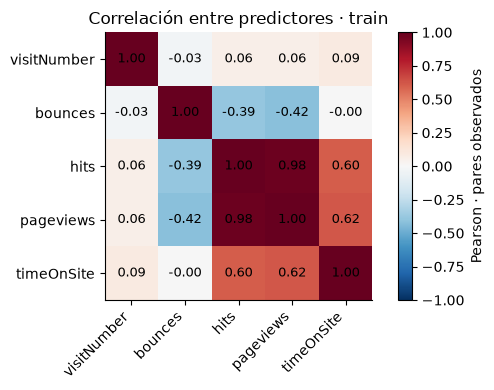

,VIF (bloque numérico)
timeOnSite_missing,213.50
bounces,212.14
pageviews,66.52
hits,61.15
timeOnSite,1.94
pageviews_missing,1.03
visitNumber,1.01


In [9]:
correlation = train[numeric_predictors].corr()
fig, ax = plt.subplots(figsize=(6, 4))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation)), correlation.index)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="Pearson · pares observados")
ax.set_title("Correlación entre predictores · train")
fig.tight_layout()
plt.show()

vif_frame = np.log1p(train[["visitNumber", "hits", "pageviews", "timeOnSite"]].astype(float))
for column in ["pageviews", "timeOnSite"]:
    vif_frame[f"{column}_missing"] = train[column].isna().astype(float)
vif_frame["bounces"] = train.bounces.astype(float)
vif_frame = vif_frame.fillna(vif_frame.median())
vif_frame = vif_frame.loc[:, vif_frame.nunique() > 1]
z = ((vif_frame - vif_frame.mean()) / vif_frame.std(ddof=0)).to_numpy()
vifs = {}
for index, column in enumerate(vif_frame):
    others = np.column_stack([np.ones(len(z)), np.delete(z, index, axis=1)])
    fitted = others @ np.linalg.lstsq(others, z[:, index], rcond=None)[0]
    unexplained_fraction = np.sum((z[:, index] - fitted)**2) / np.sum(z[:, index]**2)
    vifs[column] = np.inf if unexplained_fraction < 1e-12 else 1 / unexplained_fraction
display(pd.Series(vifs, name="VIF (bloque numérico)").sort_values(ascending=False).round(2).to_frame())


**Resultados:** VIF de 213,50 para ausencia de duración y 212,14 para rebote; 66,52 para páginas y 61,15 para acciones. La duración observada/imputada tiene VIF de 1,94 en este bloque. La señal más redundante es su ausencia frente al rebote, no necesariamente la duración misma. En correlación univariada con compra, páginas (Pearson 0,395), acciones (0,379) y duración (0,248 sobre filas observadas) destacan entre las numéricas.

**Cómo usar estos diagnósticos:** investigar esa redundancia, sin eliminar variables automáticamente. No concluir que una feature “causa” compras ni que un VIF alto obliga a quitarla. El baseline tiene regularización y árboles pueden tolerar redundancia; cualquier simplificación se compara con el mismo protocolo de validación. Además, el baseline crea indicadores explícitos y `SimpleImputer(add_indicator=True)` puede repetirlos: revisar esa redundancia en un experimento posterior, sin cambiar aquí el modelo.

Fuentes metodológicas: [Pearson, SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) y [VIF, statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).


## 8. Qué decisiones deja este EDA

**Hallazgos principales:** 392.892 sesiones y 15 columnas originales, sin duplicados exactos. Sí hay 32.798 filas adicionales con el mismo usuario y día: no son duplicados por sí mismas; al incorporar `visitNumber` no se repite esa combinación. Entre enero y mayo, la tasa de compra pasa de 1,08 % a 1,71 %, y la proporción de sesiones con historia de días previos observada va de 12,11 % a 18,60 %. Esto respalda comprobar estabilidad temporal y desempeño sin historia.

- Modelar la compra por **sesión terminada**, evitando usar el resultado de esa sesión como feature.
- Respetar faltantes según su significado y documentar la hipótesis del target.
- Conservar el split temporal y construir historia disponible al momento de cada fila.
- Comparar contra baselines y evaluar la minoría positiva; no elegir por accuracy.
- Entrenar transformaciones sólo con enero–abril y permitir sesiones sin historia.
- Mantener aquí el análisis: entrenamiento, búsqueda de hiperparámetros y selección de umbrales viven en el pipeline del proyecto.

**Próximo paso:** AutoResearch explora features/modelos optimizando log loss. Después se congela el modelo y se seleccionan umbrales con penalizaciones simuladas. Los resultados de mayo no son una evaluación independiente de esas decisiones.

Referencias: [arquitectura](../docs/architecture.md), [AutoResearch](../docs/autoresearch.md), [evaluación](../docs/evaluation.md) y [cargador de datos](../src/autoresearch_purchase_propensity/preprocess.py).
